### Exploratory Data Analysis
https://www.kaggle.com/code/georgyzubkov/store-sales-exploratory-data-analysis/input

In [11]:
import pandas as pd

df = pd.read_csv('train.csv', parse_dates=['date'])

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


### slicing a part of dataset for visualizaoitn

In [13]:
# target only to Store 1, GROCERY I
target_df = (
    df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')][['date', 'sales', 'onpromotion']]
)

print('Target dataframe shape:', target_df.shape)
target_df.head()

Target dataframe shape: (1684, 3)


,date,sales,onpromotion
12,2013-01-01,0.0,0
1794,2013-01-02,2652.0,0
3576,2013-01-03,2121.0,0
5358,2013-01-04,2056.0,0
7140,2013-01-05,2216.0,0


In [14]:
# Target series summary statistics
target_df.describe()

,date,sales,onpromotion
count,1684,1684.000000,1684.000000
mean,2015-04-24 08:27:04.703088128,2223.172803,17.560570
min,2013-01-01 00:00:00,0.000000,0.000000
25%,2014-02-26 18:00:00,1873.500000,0.000000
50%,2015-04-24 12:00:00,2283.500000,6.000000
75%,2016-06-19 06:00:00,2649.000000,28.000000
max,2017-08-15 00:00:00,9065.000000,167.000000
std,NaN,779.285352,24.741069


Plotting sliced DataFrame

<Axes: title={'center': 'Store 1 - Grocery I Sales'}, xlabel='date'>

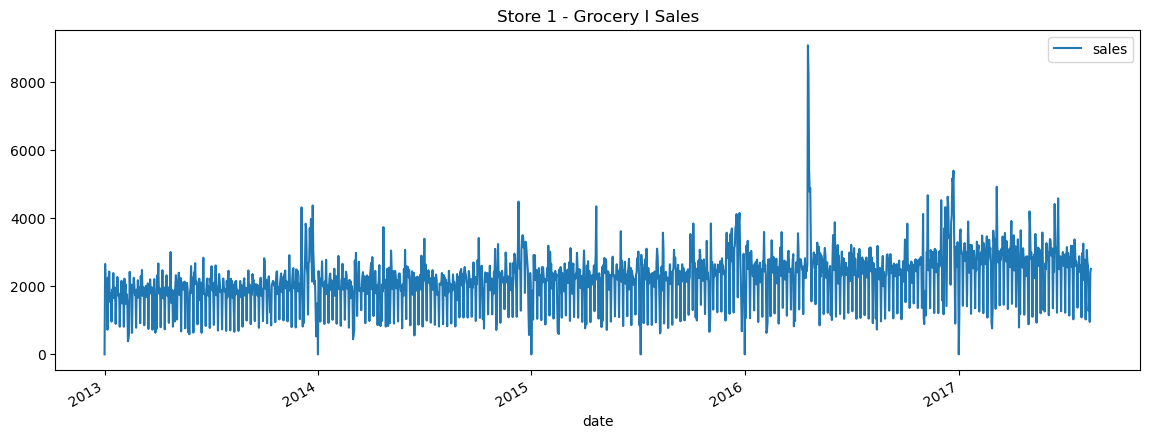

In [15]:
slice_df = target_df.copy()

slice_df.plot(x='date',
              y='sales',
              figsize=(14, 5),
              title='Store 1 - Grocery I Sales')

zooming into year 2016 to inspect that spike

<Axes: xlabel='date'>

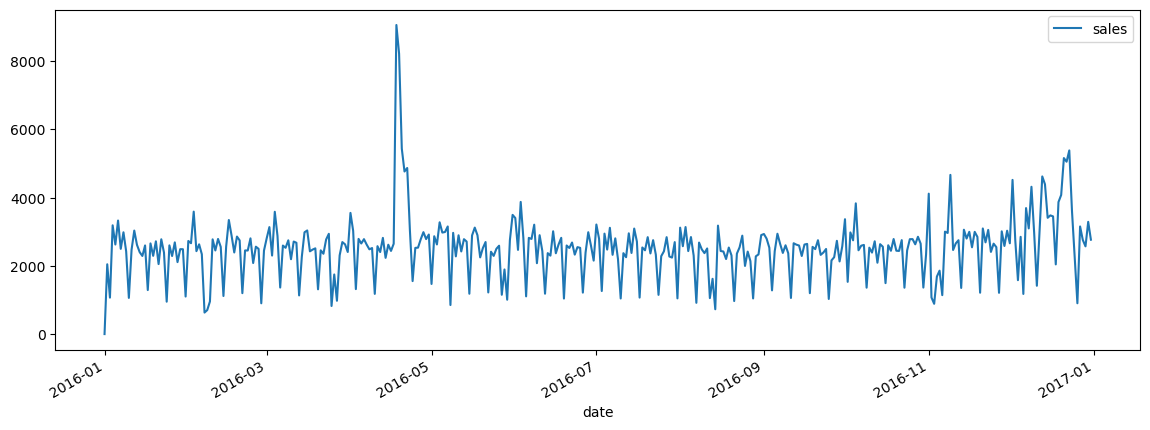

In [16]:
slice_df[(slice_df.date >= '2016-01-01')
         & (slice_df.date <= '2016-12-31')].plot(x='date',
                                                 y='sales',
                                                 figsize=(14, 5))

<Axes: xlabel='date'>

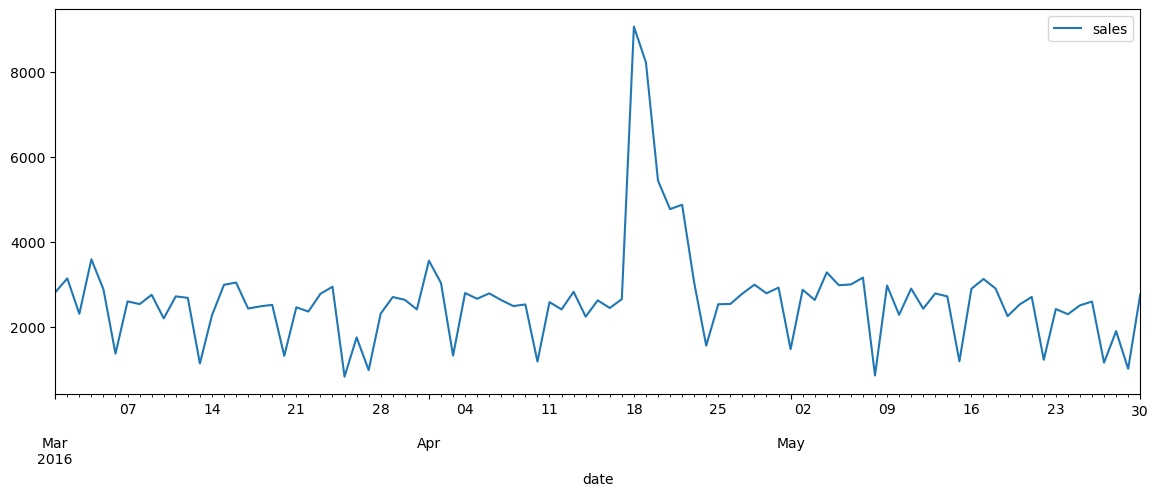

In [17]:
slice_df[(slice_df.date >= '2016-03-01')
         & (slice_df.date <= '2016-05-30')].plot(x='date',
                                                 y='sales',
                                                 figsize=(14, 5))

### Zooming into a Typical Month

To observe short-term daily fluctuations and weekly patterns, we zoom into a single representative month (May 2017).

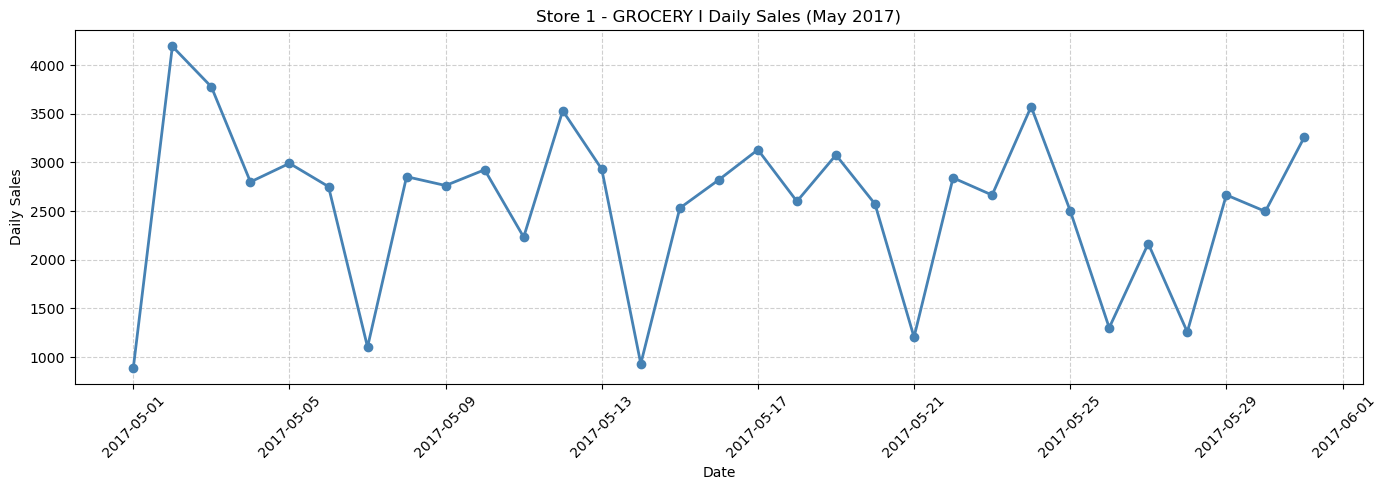

In [18]:
import matplotlib.pyplot as plt

# Zoom into May 2017 to observe day-to-day fluctuations
may_2017 = target_df[(target_df['date'] >= '2017-05-01') & (target_df['date'] <= '2017-05-31')]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(may_2017['date'], may_2017['sales'], marker='o', color='steelblue', linewidth=2)
ax.set_title('Store 1 - GROCERY I Daily Sales (May 2017)')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Sales')
ax.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Monthly aggregation
target_df['month'] = target_df['date'].dt.month
target_df['month_name'] = target_df['date'].dt.month_name()

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_stats = (target_df.groupby(
    ['month', 'month_name'])['sales'].agg(count='count',
                                          mean_sales='mean',
                                          median_sales='median',
                                          std_sales='std').reset_index())
monthly_stats

,month,month_name,count,mean_sales,median_sales,std_sales
0,1,January,155,2109.903226,2208.0,746.221171
1,2,February,141,2091.872340,2193.0,748.043418
2,3,March,155,2214.729032,2289.0,743.179387
3,4,April,150,2343.973333,2308.0,1086.937308
4,5,May,155,2183.412903,2295.0,721.858332
5,6,June,150,2268.526667,2326.5,713.742116
6,7,July,155,2178.774194,2275.0,648.262238
7,8,August,139,2033.323741,2155.0,640.865902
8,9,September,120,2126.658333,2251.5,535.530107
9,10,October,124,2224.822581,2292.5,607.689414


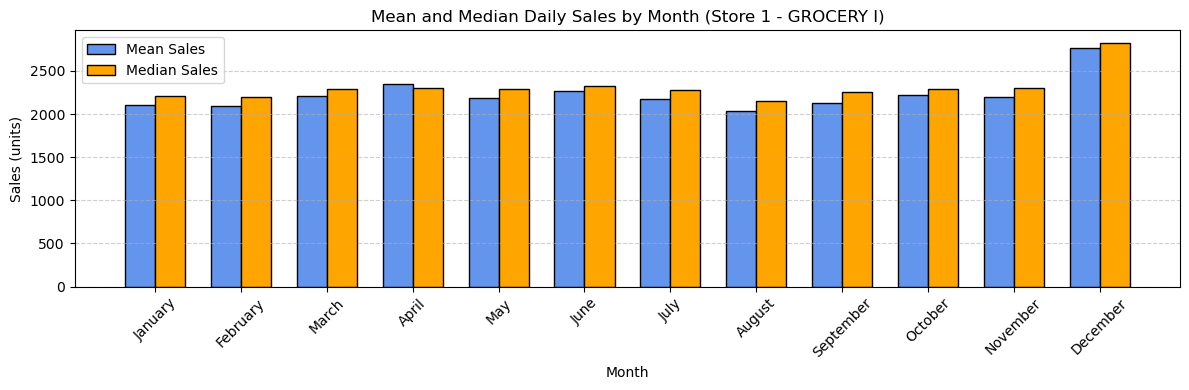

In [21]:
import numpy as np

# Comparison of mean vs median monthly sales
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(monthly_stats))
width = 0.35

ax.bar(x - width/2, monthly_stats['mean_sales'], width, label='Mean Sales', color='cornflowerblue', edgecolor='black')
ax.bar(x + width/2, monthly_stats['median_sales'], width, label='Median Sales', color='orange', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(monthly_stats['month_name'], rotation=45)
ax.set_title('Mean and Median Daily Sales by Month (Store 1 - GROCERY I)')
ax.set_xlabel('Month')
ax.set_ylabel('Sales (units)')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Monthly Patterns Observations

December shows the highest sales 
 April shows an elevated mean 